# Scorecard: what a forecaster gets right and wrong

Some of a series' future can be predicted and some cannot, by design. A
straight line can be extended forever; the noise around it never. A random
walk's next move is a coin flip; where it is now is not. A scorecard asks one
question per kind of series and per amount of noise: **how close does this
forecaster get to the best possible forecast?**

Every row below is a kind of series we can simulate exactly, so we know the
best possible forecast: the mean of the future given the history and the true
process. We call it the *answer key*. The score compares the forecaster's
error with the error the answer key itself makes, which is the noise nobody
can predict.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp grid

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `grid`

### Imports and configuration

In [3]:
#| export grid
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Callable

import numpy as np

from timegym._internal import positive_int
from timegym.scenarios import Scenario

__all__ = ["NOISE_LOW", "NOISE_HIGH", "Pattern", "PATTERNS", "GridCell", "noise_levels", "scenario_grid"]

### Ten kinds of series

Each pattern says, in plain words, what a perfect forecaster could get right and
what nobody can, then builds its Scenario for a given noise level. Noise always
means a random error on each observation, on top of the pattern. On the
autoregressive and random-walk rows that error is *measurement noise*: it hides
where the process is now, so even the answer key has to smooth the history.

Two of the rows are easy to confuse. An **autoregressive** process makes each
value a weighted sum of recent values plus a fresh shock. With one lag and a
weight below one, every gap from the average shrinks step by step, so shocks
fade: that is *mean reversion*. With a weight of exactly one nothing fades and
the series wanders: that is the *random walk*. Cycles need two lags, whose
weights can make shocks ring like a damped spring (Yule, 1927,
[doi:10.1098/rsta.1927.0007](https://doi.org/10.1098/rsta.1927.0007)).

In [4]:
#| export grid
# Noise standard deviations at the two ends of the grid, in the same units
# as the patterns below, whose signals swing by roughly 3 to 12 units.
NOISE_LOW, NOISE_HIGH = 0.5, 2.0


@dataclass(frozen=True)
class Pattern:
    """One row of the scorecard: a kind of series, in plain words.

    ``predictable`` says what a perfect forecaster could get right;
    ``unpredictable`` what no forecaster can, by design. ``build(noise,
    context_length, horizon)`` returns the Scenario for one noise level: the
    noise is the standard deviation of the random error on each observation.
    """

    key: str
    title: str
    aka: str
    predictable: str
    unpredictable: str
    build: Callable[[float, int, int], Scenario] = field(repr=False, compare=False)


def _cycle_coefficients(period=16.0, damping=0.95):
    """AR(2) weights whose shocks ring at ``period`` steps and fade by ``damping`` per step."""
    return 2 * damping * np.cos(2 * np.pi / period), -damping**2


_PHI1, _PHI2 = _cycle_coefficients()

PATTERNS = {pattern.key: pattern for pattern in (
    Pattern("noise", "Pure noise", "white noise around zero",
            "Only the average, zero: the best forecast is a flat line at zero.",
            "Every individual value. Any pattern a model finds here is invented.",
            lambda s, n, h: Scenario("white_noise", n, h, {"mean": 0.0, "sigma": s})),
    Pattern("level", "Noise around a fixed level", "white noise with a constant mean of 10",
            "The level, estimated from the whole history.",
            "Each wiggle around the level.",
            lambda s, n, h: Scenario("white_noise", n, h, {"mean": 10.0, "sigma": s})),
    Pattern("trend", "Straight-line trend", "linear trend + white noise, slope 0.1 per step",
            "The line, extended any number of steps ahead.",
            "The noise around the line.",
            lambda s, n, h: Scenario("trend", n, h, {"slope": 0.1, "sigma": s})),
    Pattern("seasonal", "Repeating seasonal cycle", "fixed seasonality + white noise, period 12",
            "The repeating shape, any number of steps ahead.",
            "The noise around the cycle.",
            lambda s, n, h: Scenario("seasonal", n, h, {"amplitude": 3.0, "period": 12.0, "sigma": s})),
    Pattern("trend_seasonal", "Trend + seasonal cycle", "linear trend + seasonality + white noise",
            "Both the line and the repeating shape.",
            "The noise around them.",
            lambda s, n, h: Scenario("composite", n, h, {"slope": 0.1, "amplitude": 3.0, "period": 12.0,
                                                         "sigma": s})),
    Pattern("level_shift", "Sudden level shift", "a one-off break: the last quarter of the history jumped by 6",
            "The new level, from the history since the jump.",
            "The noise. Older history sits at the old level and misleads.",
            lambda s, n, h: Scenario("composite", n, h, {"sigma": s, "change_point": n - max(1, n // 4),
                                                         "changes": {"intercept": 6.0}})),
    Pattern("mean_reverting", "Mean reversion (AR(1)): shocks fade",
            "stationary autoregressive process, each gap from the average keeps 0.8 of itself per step",
            "The pull back to the average: a gap halves in about three steps.",
            "New shocks. After about ten steps only the average is left; "
            "measurement noise hides where the series is now.",
            lambda s, n, h: Scenario("ar1", n, h, {"phi": 0.8, "sigma": 1.0, "noise": s})),
    Pattern("cycles", "Irregular cycles (AR(2))",
            "autoregressive process with two lags whose shocks ring with a period of about 16 steps",
            "The rest of the current swing, fading over the next cycles.",
            "When the next swings come and how big they are; noise hides the current phase.",
            lambda s, n, h: Scenario("ar2", n, h, {"phi1": _PHI1, "phi2": _PHI2, "sigma": 0.5, "noise": s})),
    Pattern("random_walk", "Random walk: shocks never fade", "AR(1) with weight 1 (a unit root)",
            "Where it is now: the best forecast is flat at the current level, smoothed when noisy.",
            "The direction of the next move. Uncertainty grows without limit with the horizon.",
            lambda s, n, h: Scenario("random_walk", n, h, {"sigma": 0.5, "noise": s})),
    Pattern("random_walk_drift", "Random walk with drift", "a unit root plus a steady push of 0.1 per step",
            "The current level plus the steady drift.",
            "The wandering around the drift line, which grows with the horizon.",
            lambda s, n, h: Scenario("random_walk", n, h, {"drift": 0.1, "sigma": 0.5, "noise": s})),
)}

### Cells and noise levels

Two noise levels by default, low and high, chosen to be clearly different but
not extreme: at high noise every pattern is still there to be found. More
levels fill the range between the same two ends, spaced evenly on a log scale.

In [5]:
#| export grid
@dataclass(frozen=True)
class GridCell:
    """One pattern at one noise level: its labels and its Scenario."""

    pattern: str
    title: str
    noise: str
    noise_sd: float
    scenario: Scenario = field(repr=False)


def noise_levels(levels=2):
    """Return ``(name, sd)`` pairs from low to high noise.

    An integer ``n >= 2`` spaces ``n`` levels geometrically between
    ``NOISE_LOW`` and ``NOISE_HIGH``, so every grid keeps both extremes and
    fills the range between them. A sequence of positive standard deviations
    is used as given, sorted.
    """
    if isinstance(levels, (int, np.integer)) and not isinstance(levels, bool):
        count = positive_int(levels, "noise_levels")
        if count < 2:
            raise ValueError("noise_levels needs at least two levels: low and high")
        sds = np.geomspace(NOISE_LOW, NOISE_HIGH, count)
    else:
        sds = np.sort(np.asarray(list(levels), dtype=float))
        if sds.ndim != 1 or len(sds) == 0 or not np.all(np.isfinite(sds)) or np.any(sds <= 0):
            raise ValueError("noise_levels must be an integer >= 2 or a sequence of positive numbers")
    names = {2: ["Low noise", "High noise"], 3: ["Low noise", "Medium noise", "High noise"]}.get(len(sds))
    if names is None or not isinstance(levels, (int, np.integer)):
        names = [f"Noise sd {sd:.3g}" for sd in sds]
        if isinstance(levels, (int, np.integer)):
            names[0], names[-1] = "Low noise", "High noise"
    return [(name, float(sd)) for name, sd in zip(names, sds)]


def scenario_grid(patterns=None, noise_levels=2, *, context_length=120, horizon=24):
    """Return one GridCell per pattern and noise level, rows first.

    ``patterns`` lists keys of ``PATTERNS`` (all ten by default, in their
    order). ``noise_levels`` is as in ``noise_levels()``: two by default, low
    and high. Scenarios carry no seed of their own; the run supplies it.
    """
    keys = list(PATTERNS) if patterns is None else list(patterns)
    unknown = [key for key in keys if key not in PATTERNS]
    if unknown or not keys or len(set(keys)) != len(keys):
        raise ValueError(f"patterns must be distinct keys from {tuple(PATTERNS)}; got {keys}")
    context_length = positive_int(context_length, "context_length")
    horizon = positive_int(horizon, "horizon")
    if context_length < 8:
        raise ValueError("The scorecard grid needs a context_length of at least 8")
    levels = _noise_levels(noise_levels)
    return [GridCell(key, PATTERNS[key].title, name, sd, PATTERNS[key].build(sd, context_length, horizon))
            for key in keys for name, sd in levels]


_noise_levels = noise_levels

In [6]:
# Keep the live grid definitions; the scorecard module below imports exported copies.
_notebook_grid = (Pattern, PATTERNS, GridCell, noise_levels, scenario_grid)

## Build `scorecard`

### Imports and configuration

In [7]:
#| export scorecard
from __future__ import annotations

import io
import textwrap
from dataclasses import dataclass

import numpy as np
import pandas as pd

from timegym._internal import positive_int
from timegym.contracts import _describe_shift, _index_shift
from timegym.evaluation import ForecastRun
from timegym.grid import PATTERNS, GridCell, scenario_grid
from timegym.plotting import _BAND_COLORS, _FORECAST, _HAIRLINE, _INK, _MUTED, _SURFACE
from timegym.reporting import CHECKS, TestReport, _case_checks

__all__ = ["VERDICTS", "verdict", "Scorecard", "scorecard"]

### One number per cell

For each instance we know two errors. The **unavoidable** error is the mean
variance of the future around the answer key: what a forecaster that knows the
process still gets wrong. The **avoidable** error is the mean squared distance
from the forecast to the answer key. The score is

$$\text{score} = 100 \times \frac{\text{unavoidable}}{\text{unavoidable} + \text{avoidable}}$$

pooled over a cell's instances. 100 is as good as knowing the process; 50 means
the forecaster adds as much error as the noise itself. Because the avoidable
part is measured against the answer key rather than against one noisy future,
a few instances already settle it. The bands (90 nails it, 70 good, 40
struggles) are for reading, not for passing.

In [8]:
#| export scorecard
# Display bands for the 0-100 score. They describe; they are not tests.
VERDICTS = ((90, "Nails it"), (70, "Good"), (40, "Struggles"), (0, "Fails"))


def verdict(score):
    """Name the band of a 0-100 score; ``None`` (nothing scorable) stays ``None``."""
    if score is None or not np.isfinite(score):
        return None
    shown = round(score)  # the band agrees with the number printed beside it
    return next(name for floor, name in VERDICTS if shown >= floor)


def _case_numbers(entry):
    """Return ``(best, avoidable, errors, truth)`` for a scorable case, else None.

    ``best`` is the unavoidable error: the mean conditional variance of the
    future, the error a forecaster that knows the process still makes.
    ``avoidable`` is the mean squared distance from the forecast to the true
    conditional mean (the answer key). Samples stand in for a missing point
    forecast through their mean.
    """
    forecast, case = entry.forecast, entry.case
    if forecast is None or case.reference is None or not all(_case_checks(entry.result).values()):
        return None
    if forecast.point is not None:
        point = np.asarray(forecast.point, dtype=float)
    elif forecast.samples is not None:
        point = np.asarray(forecast.samples, dtype=float).mean(axis=0)
    else:
        return None
    truth = np.asarray(case.reference.mean, dtype=float)
    errors = point - truth
    return float(np.mean(case.reference.variance)), float(np.mean(errors**2)), errors, truth


def _score(best, avoidable):
    """100 * unavoidable / (unavoidable + avoidable) error: 100 is a perfect forecaster."""
    total = best + avoidable
    return 100.0 if total == 0 else 100.0 * best / total

### Naming the mistakes

A low score says *that* a forecaster misses; the error's shape says *how*.
Against the answer key, each instance's error splits exactly into a constant
offset, a straight-line drift over the horizon and the rest. Whichever part
carries the avoidable error names the mistake: forecasts too low, a trend too
flat, a missed cycle. A forecast that matches the answer key one step off is
reported as shifted, and failed output checks (wrong dates, crashes) come
first.

In [9]:
#| export scorecard
def _detrend(values):
    """Split rows of ``values`` into mean, slope per step and what remains."""
    steps = np.arange(values.shape[1]) - (values.shape[1] - 1) / 2
    level = values.mean(axis=1)
    spread = np.sum(steps**2)
    slope = values @ steps / spread if spread else np.zeros(len(values))
    return level, slope, values - level[:, None] - slope[:, None] * steps


def _mistakes(numbers):
    """Name up to two systematic mistakes behind a cell's avoidable error.

    Each instance's error against the answer key splits exactly into a
    constant offset (level), a straight-line drift over the horizon (trend)
    and the rest (shape); their mean squares add up to the avoidable error.
    A level or shape part carrying at least 25% of it is named. Signs that
    agree across 80% of instances make a level error "too high" or "too
    low". A trend is named when its part carries at least 10% and the slope
    error adds up, over the horizon, to at least half the noise's standard
    deviation, and the answer key is itself mostly a line over the horizon
    (a cycle's slope is not a trend) or flat ("invents a trend"). A shape error is a missed cycle, one
    out of step (correlation below 0.5), an exaggerated one or wiggles the
    answer key does not have. A forecast that matches the answer key one step earlier or
    later at least four times better than at its own dates, on a series
    with shape, is reported as shifted instead.
    """
    errors = np.concatenate([n[2].T for n in numbers])
    truth = np.concatenate([n[3].T for n in numbers])
    forecast = truth + errors
    best = np.mean([n[0] for n in numbers])
    horizon = errors.shape[1]
    offset, drift, rest = _detrend(errors)
    _, truth_slope, truth_rest = _detrend(truth)
    _, forecast_slope, forecast_rest = _detrend(forecast)
    steps = np.arange(horizon) - (horizon - 1) / 2
    parts = {"level": np.mean(offset**2), "trend": np.mean(drift**2) * np.mean(steps**2),
             "shape": np.mean(rest**2)}
    total = sum(parts.values())
    if total == 0:
        return []
    truth_shape = np.mean(truth_rest**2)
    if horizon >= 4 and truth_shape > 0:
        inner = forecast[:, 1:-1]
        aligned = np.mean((inner - truth[:, 1:-1]) ** 2)
        late, early = np.mean((inner - truth[:, :-2]) ** 2), np.mean((inner - truth[:, 2:]) ** 2)
        if aligned > 0.25 * best and truth_shape > 0.25 * aligned and min(late, early) < 0.25 * aligned:
            return ["Values one step late" if late < early else "Values one step early"]
    found = []
    for part, size in sorted(parts.items(), key=lambda item: -item[1]):
        if part == "level" and size >= 0.25 * total:
            share_high = np.mean(offset > 0)
            found.append("Forecasts too high" if share_high >= 0.8 else
                         "Forecasts too low" if share_high <= 0.2 else "Misreads the current level")
        elif part == "trend" and size >= 0.1 * total and np.mean(np.abs(drift)) * horizon >= 0.5 * np.sqrt(best):
            typical = np.mean(np.abs(truth_slope))
            line_share = np.mean(truth_slope**2) * np.mean(steps**2) / max(np.mean(truth.var(axis=1)), 1e-300)
            if typical * horizon < 0.5 * np.sqrt(best):
                found.append("Invents a trend")
            elif line_share >= 0.5:
                ratio = np.mean(forecast_slope * np.sign(truth_slope)) / typical
                found.append("Trend too flat" if ratio < 0.5 else
                             "Trend too steep" if ratio > 1.5 else "Misjudges the trend")
        elif part == "shape" and size >= 0.25 * total:
            truth_amplitude, forecast_amplitude = np.sqrt(truth_shape), np.sqrt(np.mean(forecast_rest**2))
            if truth_amplitude < 0.25 * np.sqrt(best):
                found.append("Too wiggly")
            elif forecast_amplitude < 0.5 * truth_amplitude:
                found.append("Misses the cycle")
            elif np.mean(forecast_rest * truth_rest) < 0.5 * forecast_amplitude * truth_amplitude:
                found.append("Cycle out of step")
            elif forecast_amplitude > 1.5 * truth_amplitude:
                found.append("Exaggerates the cycle")
            else:
                found.append("Too wiggly")
    return found[:2]


def _check_problems(entries):
    """Describe failed output checks in a cell, with date shifts in steps."""
    problems = {}
    for entry in entries:
        for key, passed in _case_checks(entry.result).items():
            if passed:
                continue
            text = CHECKS[key]
            if key == "runs":
                text = "Crashes"
            elif key == "dates" and entry.forecast is not None:
                shift = _index_shift(entry.forecast.index, entry.case.task.future_index)
                text = "Wrong dates" + (f": {_describe_shift(shift)}" if shift else "")
            else:
                text = f"Fails check: {text.lower()}"
            problems[text] = problems.get(text, 0) + 1
    return [f"{text} ({count} of {len(entries)})" for text, count in problems.items()]

### Building a scorecard

In [10]:
#| export scorecard
def _mistake_notes(rows):
    """One line per noise level that has mistakes, or one line when every level has the same."""
    found = [(row.noise, row.mistakes) for row in rows.itertuples()]
    same = {frozenset(m.split("; ")) for _, m in found}
    if len(found) > 1 and found[0][1] and len(same) == 1:
        return [found[0][1]]
    return [f"{noise.replace(' noise', '')}: {m}" for noise, m in found if m]


def _model_title(pipeline):
    """A short, readable name for the model a pipeline evaluates."""
    if pipeline.steps:
        names = " → ".join(type(step).__name__ for step in pipeline.steps)
        return f"{names} ({pipeline.reduction}, window {pipeline.window_length})"
    if pipeline.model_factory is not None:
        return getattr(pipeline.model_factory, "__qualname__", "model_factory")
    model = pipeline.model
    if model is None:
        from timegym.models import NaiveForecaster

        model = NaiveForecaster()
    if isinstance(model, type):
        return model.__name__
    params = getattr(model, "params", None)
    if callable(params):
        arguments = ", ".join(f"{key}={value!r}" for key, value in params().items())
        return f"{type(model).__name__}({arguments})"
    return type(model).__name__


def scorecard(pipeline, patterns=None, *, noise_levels=2, instances=10, seed=0, context_length=120,
              horizon=24, title=None):
    """Run ``pipeline`` on the pattern-by-noise grid and score every cell.

    Each cell is ``instances`` independent series (seeds ``seed + i``, the
    same draws in every cell, so the noise columns are a paired comparison).
    A cell's score is ``100 * unavoidable / (unavoidable + avoidable)`` mean
    squared error, pooled over its instances: 100 is as close as a forecaster
    that knows the process; 50 means the avoidable error equals the
    unavoidable noise. Instances that crash or fail an output check score
    zero. ``seed=None`` picks a fresh seed, kept on the result.
    """
    instances = positive_int(instances, "instances")
    cells = scenario_grid(patterns, noise_levels, context_length=context_length, horizon=horizon)
    run = pipeline.run([cell.scenario for cell in cells], seed=seed, instances=instances)
    run.titles = [f"{cell.title} · {cell.noise}" for cell in cells]  # plain row titles for run.plot_*
    by_cell = {}
    for entry in run.cases:
        by_cell.setdefault(entry.scenario_index, []).append(entry)
    rows = []
    for index, cell in enumerate(cells):
        entries = by_cell[index]
        numbers = [found for found in map(_case_numbers, entries) if found]
        broken = sum(not all(_case_checks(entry.result).values()) for entry in entries)
        scorable = len(numbers) + broken
        best = float(np.mean([n[0] for n in numbers])) if numbers else np.nan
        avoidable = float(np.mean([n[1] for n in numbers])) if numbers else np.nan
        score = (_score(best, avoidable) * len(numbers) / scorable if numbers
                 else (0.0 if broken else np.nan))
        mistakes = _check_problems(entries)
        if numbers and round(score) < 70:  # as the verdict reads it
            mistakes += _mistakes(numbers)
        observed = [entry.result.metrics["mse"] for entry in entries if "mse" in entry.result.metrics]
        rows.append({"pattern": cell.pattern, "title": cell.title, "noise": cell.noise,
                     "noise_sd": cell.noise_sd, "score": score, "verdict": verdict(score),
                     "mistakes": "; ".join(mistakes), "unavoidable_mse": best, "avoidable_mse": avoidable,
                     "mse": float(np.mean(observed)) if observed else np.nan,
                     "instances": len(entries), "failed_checks": broken})
    return Scorecard(title=title or _model_title(pipeline), table=pd.DataFrame(rows), run=run, cells=cells,
                     seed=run.metadata["seed"], instances=instances)

### The Scorecard

In [11]:
#| export scorecard
@dataclass(repr=False)
class Scorecard:
    """What a forecaster gets right and wrong across kinds of series and noise.

    ``table`` has one row per pattern and noise level: the 0-100 ``score``,
    its ``verdict``, named ``mistakes``, the unavoidable and avoidable mean
    squared errors behind the score, and the mean squared error against what
    happened (``mse``). ``run`` keeps every series and forecast for plots;
    ``report`` is the JSON-ready TestReport. In a notebook a Scorecard shows
    as its image; ``print`` gives Markdown and ``save`` writes the image.
    """

    title: str
    table: pd.DataFrame
    run: ForecastRun
    cells: list[GridCell]
    seed: int
    instances: int

    @property
    def score(self):
        """Overall 0-100 score: the mean of the cell scores."""
        values = self.table["score"].dropna()
        return float(values.mean()) if len(values) else float("nan")

    @property
    def report(self) -> TestReport:
        """The structured report of every case, for JSON or ``assert_passed``."""
        return self.run.report

    def _by_pattern(self):
        return self.table.groupby("pattern", sort=False)["score"]

    @property
    def good_at(self):
        """Patterns scoring at least 70 at every noise level."""
        lowest = self._by_pattern().min()
        return [PATTERNS[key].title for key, value in lowest.items() if value >= 70]

    @property
    def fails_at(self):
        """Patterns scoring below 40 at some noise level."""
        lowest = self._by_pattern().min()
        return [PATTERNS[key].title for key, value in lowest.items() if value < 40]

    @property
    def noise_sensitive(self):
        """Patterns whose score drops by 25 points or more from low to high noise."""
        scores = self._by_pattern()
        return [PATTERNS[key].title for key, values in scores
                if len(values) > 1 and values.iloc[0] - values.iloc[-1] >= 25]

    @property
    def checks(self):
        """Output checks with pass/fail counts, as in ``TestReport.checks``."""
        return self.report.checks

    def __repr__(self):
        return (f"Scorecard({self.title!r}, score={self.score:.0f}/100, "
                f"{self.table['pattern'].nunique()} patterns x {self.table['noise'].nunique()} noise levels, "
                f"{self.instances} instances, seed={self.seed})")

    def to_markdown(self):
        """Return the scorecard as a Markdown summary and table."""
        levels = list(dict.fromkeys(self.table["noise"]))
        lines = [f"## {self.title}: {self.score:.0f}/100", "",
                 f"TimeGym scorecard: {_count(self.table['pattern'].nunique(), 'kind of series', 'kinds of series')}"
                 f" x {_count(len(levels), 'noise level', 'noise levels')}, "
                 f"{_count(self.instances, 'instance', 'instances')} each, seed {self.seed}.", "",
                 "| Pattern | " + " | ".join(levels) + " | Mistakes |",
                 "|---|" + "---|" * len(levels) + "---|"]
        for key, rows in self.table.groupby("pattern", sort=False):
            cells = [f"{row.score:.0f} {row.verdict}" if np.isfinite(row.score) else "not scored"
                     for row in rows.itertuples()]
            mistakes = " · ".join(_mistake_notes(rows)) or "none found"
            lines.append(f"| {PATTERNS[key].title} | " + " | ".join(cells) + f" | {mistakes} |")
        lines += ["", f"**Good at:** {', '.join(self.good_at) or 'none'}.",
                  f"**Fails at:** {', '.join(self.fails_at) or 'none'}."]
        if self.noise_sensitive:
            lines.append(f"**Breaks down under heavy noise:** {', '.join(self.noise_sensitive)}.")
        lines += ["", "**Output checks:** " + " · ".join(
            f"{'✓' if not row['failed'] else '✗'} {row['title']} ({row['passed']}/{row['passed'] + row['failed']})"
            for row in self.checks), "", _LEGEND]
        return "\n".join(lines)

    def __str__(self):
        return self.to_markdown()

    def plot(self, *, compact=False):
        """Draw the scorecard and return the matplotlib Figure.

        The full figure has one row per pattern: what can and cannot be
        predicted, an example forecast with its score at each noise level, and
        the mistakes found. ``compact=True`` draws only the colored scores.
        """
        return _plot_scorecard(self, compact=compact)

    def save(self, path, *, compact=False, dpi=150):
        """Save the image; the file extension picks the format (png, svg, pdf)."""
        import matplotlib.pyplot as plt

        figure = self.plot(compact=compact)
        figure.savefig(path, dpi=dpi, facecolor=figure.get_facecolor())
        plt.close(figure)
        return path

    def _repr_png_(self):
        import matplotlib.pyplot as plt

        figure = self.plot()
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", dpi=100, facecolor=figure.get_facecolor())
        plt.close(figure)
        return buffer.getvalue()


_LEGEND = ("Score: 100 = as close as a forecaster that knows the true process; 50 = its avoidable error "
           "equals the unavoidable noise. Bands: 90+ nails it, 70+ good, 40+ struggles, below 40 fails.")

### Drawing it

One row per pattern. The first column says what can and cannot be predicted;
each noise column shows one example forecast under its score; the last column
lists the mistakes found. Gray dots are observations, the black line is the
answer key and blue crosses are the forecast.

In [12]:
#| export scorecard
# The palette and band colors come from timegym.plotting, shared by every figure.


def _count(number, one, many):
    """``1 kind of series``, ``10 kinds of series``."""
    return f"{number} {one if number == 1 else many}"


def _wrap(text, width):
    return "\n".join(textwrap.wrap(text, width=width, break_long_words=False))


def _badge(row):
    if row.failed_checks == row.instances:
        return "✗ broken", _BAND_COLORS[None]
    if not np.isfinite(row.score):
        return "not scored", _BAND_COLORS[None]
    return f"{row.score:.0f}  {row.verdict}", _BAND_COLORS[row.verdict]


def _example(ax, entry, row):
    """Draw instance 1 of a cell: recent history, what happened, answer key, forecast."""
    case, horizon = entry.case, len(entry.case.task.future_index)
    context = case.task.context.iloc[-min(len(case.task.context), 4 * horizon):, 0]
    ax.plot(context.index, context.to_numpy(), ".", color=_MUTED, markersize=2.2, alpha=0.75)
    ax.plot(case.observed.index, case.observed.iloc[:, 0].to_numpy(), ".", color=_MUTED, markersize=2.2,
            alpha=0.75)
    if case.reference is not None:
        ax.plot(case.task.future_index, np.asarray(case.reference.mean)[:, 0], color=_INK, linewidth=1.1)
    ax.axvline(context.index[-1] + 0.5, color=_HAIRLINE, linewidth=0.8, linestyle="--")
    valid = entry.forecast is not None and all(_case_checks(entry.result).values())
    point = None
    if valid and entry.forecast.point is not None:
        point = np.asarray(entry.forecast.point, dtype=float)[:, 0]
    elif valid and entry.forecast.samples is not None:
        point = np.asarray(entry.forecast.samples, dtype=float).mean(axis=0)[:, 0]
    if point is not None:
        ax.plot(case.task.future_index, point, "x", color=_FORECAST, markersize=2.8, markeredgewidth=0.8)
    elif row.mistakes:
        ax.text(0.98, 0.5, _wrap(row.mistakes.split(";")[0], 26), transform=ax.transAxes, ha="right",
                va="center", fontsize=8, color=_INK, bbox={"facecolor": _SURFACE, "edgecolor": _HAIRLINE})
    ax.set_xticks([])
    ax.set_yticks([])
    for side, spine in ax.spines.items():
        spine.set_visible(side == "bottom")
        spine.set_color(_HAIRLINE)


def _plot_scorecard(card, *, compact=False):
    import matplotlib.pyplot as plt

    table = card.table
    keys = list(dict.fromkeys(table["pattern"]))
    levels = list(dict.fromkeys(table["noise"]))
    sds = list(dict.fromkeys(table["noise_sd"]))
    first = {}
    for entry in card.run.cases:
        first.setdefault(entry.scenario_index, entry)
    rows_by_cell = {(row.pattern, row.noise): (index, row) for index, row in enumerate(table.itertuples())}
    good, fails = card.good_at, card.fails_at
    headline = f"{card.title}: {card.score:.0f}/100"
    subtitle = (f"TimeGym scorecard · {_count(len(keys), 'kind of series', 'kinds of series')} × "
                f"{_count(len(levels), 'noise level', 'noise levels')} · "
                f"{_count(card.instances, 'instance', 'instances')} each · seed {card.seed}")
    verdict_lines = [f"Good at: {', '.join(good) or 'none'}.", f"Fails at: {', '.join(fails) or 'none'}."]
    if card.noise_sensitive:
        verdict_lines.append(f"Breaks under heavy noise: {', '.join(card.noise_sensitive)}.")
    verdicts = "   ".join(verdict_lines)
    checks = "Output checks:  " + "    ".join(
        f"{'✓' if not row['failed'] else '✗'} {row['title']}"
        + (f" ({row['failed']} failed)" if row["failed"] else "") for row in card.checks)
    style = {"font.size": 9, "figure.facecolor": _SURFACE, "axes.facecolor": _SURFACE, "text.color": _INK,
             "font.family": "DejaVu Sans"}
    with plt.rc_context(style):
        if compact:
            width = 3.1 + 1.45 * len(levels) + 3.6
            figure = plt.figure(figsize=(width, 1.45 + 0.42 * len(keys)))
            top = 1 - 0.95 / figure.get_figheight()
            grid = figure.add_gridspec(len(keys) + 1, len(levels) + 2, left=0.01, right=0.99, top=top,
                                       bottom=0.02, hspace=0.12, wspace=0.05,
                                       width_ratios=[3.1] + [1.45] * len(levels) + [3.6],
                                       height_ratios=[0.8] + [1] * len(keys))
            figure.text(0.01, 1 - 0.18 / figure.get_figheight(), headline, fontsize=14, weight="bold", va="top")
            figure.text(0.01, 1 - 0.52 / figure.get_figheight(), _wrap(verdicts, int(width * 15)), fontsize=8.5,
                        va="top", color=_MUTED)
        else:
            width = 4.6 + 3.3 * len(levels) + 3.0
            verdict_text = "\n".join(_wrap(line, int(width * 13)) for line in verdict_lines)
            checks_at = 0.95 + 0.24 * (verdict_text.count("\n") + 1) + 0.1
            height = checks_at + 0.75 + 1.5 * len(keys) + 0.45
            figure = plt.figure(figsize=(width, height))
            top = 1 - (checks_at + 0.45) / height
            grid = figure.add_gridspec(len(keys) + 1, len(levels) + 2, left=0.012, right=0.99, top=top,
                                       bottom=0.45 / height, hspace=0.42, wspace=0.08,
                                       width_ratios=[4.6] + [3.3] * len(levels) + [3.0],
                                       height_ratios=[0.25] + [1] * len(keys))
            figure.text(0.012, 1 - 0.2 / height, headline, fontsize=17, weight="bold", va="top")
            figure.text(0.012, 1 - 0.62 / height, subtitle, fontsize=10, va="top", color=_MUTED)
            figure.text(0.012, 1 - 0.95 / height, verdict_text, fontsize=10, va="top", linespacing=1.4)
            figure.text(0.012, 1 - checks_at / height, _wrap(checks, int(width * 14)), fontsize=8.5, va="top",
                        color=_MUTED)
            figure.text(0.012, 0.32 / height, _wrap(_LEGEND + " Panels show instance 1: gray dots are "
                        "observations, the black line is the answer key, blue crosses are the forecast.",
                        int(width * 15)), fontsize=8, va="top", color=_MUTED)
        noise_headers = [f"{level} (sd {sd:g})" for level, sd in zip(levels, sds)]
        if compact and any(len(header) > 18 for header in noise_headers):
            # Narrow columns: every noise sd goes under its name, so the headers line up.
            noise_headers = [f"{level}\n(sd {sd:g})" for level, sd in zip(levels, sds)]
        headers = ([("Pattern" if compact else "What can and can't be predicted")]
                   + noise_headers + ["Mistakes"])
        for column, header in enumerate(headers):
            ax = figure.add_subplot(grid[0, column])
            ax.set_axis_off()
            ax.text(0, 0, header, fontsize=9.5, weight="bold", va="bottom", color=_INK)
        for row_number, key in enumerate(keys, start=1):
            pattern = PATTERNS[key]
            ax = figure.add_subplot(grid[row_number, 0])
            ax.set_axis_off()
            if compact:
                ax.text(0, 0.5, pattern.title, fontsize=9.5, weight="bold", va="center")
            else:
                ax.text(0, 1, pattern.title, fontsize=10.5, weight="bold", va="top")
                ax.text(0, 0.8, _wrap(pattern.aka, 60), fontsize=8, style="italic", color=_MUTED, va="top")
                body = f"✓ {_wrap(pattern.predictable, 54)}\n✗ {_wrap(pattern.unpredictable, 54)}"
                ax.text(0, 0.52, body, fontsize=8.6, va="top", linespacing=1.3)
            notes = _mistake_notes(table.loc[table["pattern"] == key])
            for column, level in enumerate(levels, start=1):
                index, row = rows_by_cell[(key, level)]
                label, (fill, ink) = _badge(row)
                ax = figure.add_subplot(grid[row_number, column])
                if compact:
                    ax.set_axis_off()
                    ax.add_patch(plt.Rectangle((0.03, 0.08), 0.94, 0.84, transform=ax.transAxes,
                                               facecolor=fill, edgecolor=_SURFACE))
                    ax.text(0.5, 0.5, label, transform=ax.transAxes, ha="center", va="center", color=ink,
                            fontsize=9, weight="bold")
                else:
                    _example(ax, first[index], row)
                    ax.text(0.0, 1.03, f" {label} ", transform=ax.transAxes, va="bottom", ha="left",
                            fontsize=9, weight="bold", color=ink,
                            bbox={"facecolor": fill, "edgecolor": "none", "boxstyle": "round,pad=0.25"})
            ax = figure.add_subplot(grid[row_number, len(levels) + 1])
            ax.set_axis_off()
            text = "\n".join(_wrap(note, 40 if not compact else 52) for note in notes) or "None found"
            ax.text(0, 0.5 if compact else 0.85, text, fontsize=8.6 if not compact else 7.5,
                    va="center" if compact else "top", color=_INK if notes else _MUTED, linespacing=1.25)
    return figure

In [13]:
# The examples must use the grid defined in this notebook, not an older export.
Pattern, PATTERNS, GridCell, noise_levels, scenario_grid = _notebook_grid
_noise_levels = noise_levels
assert scenario_grid.__module__ == Scorecard.__module__ == __name__
assert scorecard.__globals__["scenario_grid"] is scenario_grid

## The simplest forecaster

Repeat the last value. Its scorecard should agree with what we know about each
pattern: on a random walk the last value *is* the best forecast, so it should
nail it at low noise; on a seasonal cycle it ignores the shape, so it should
fail.

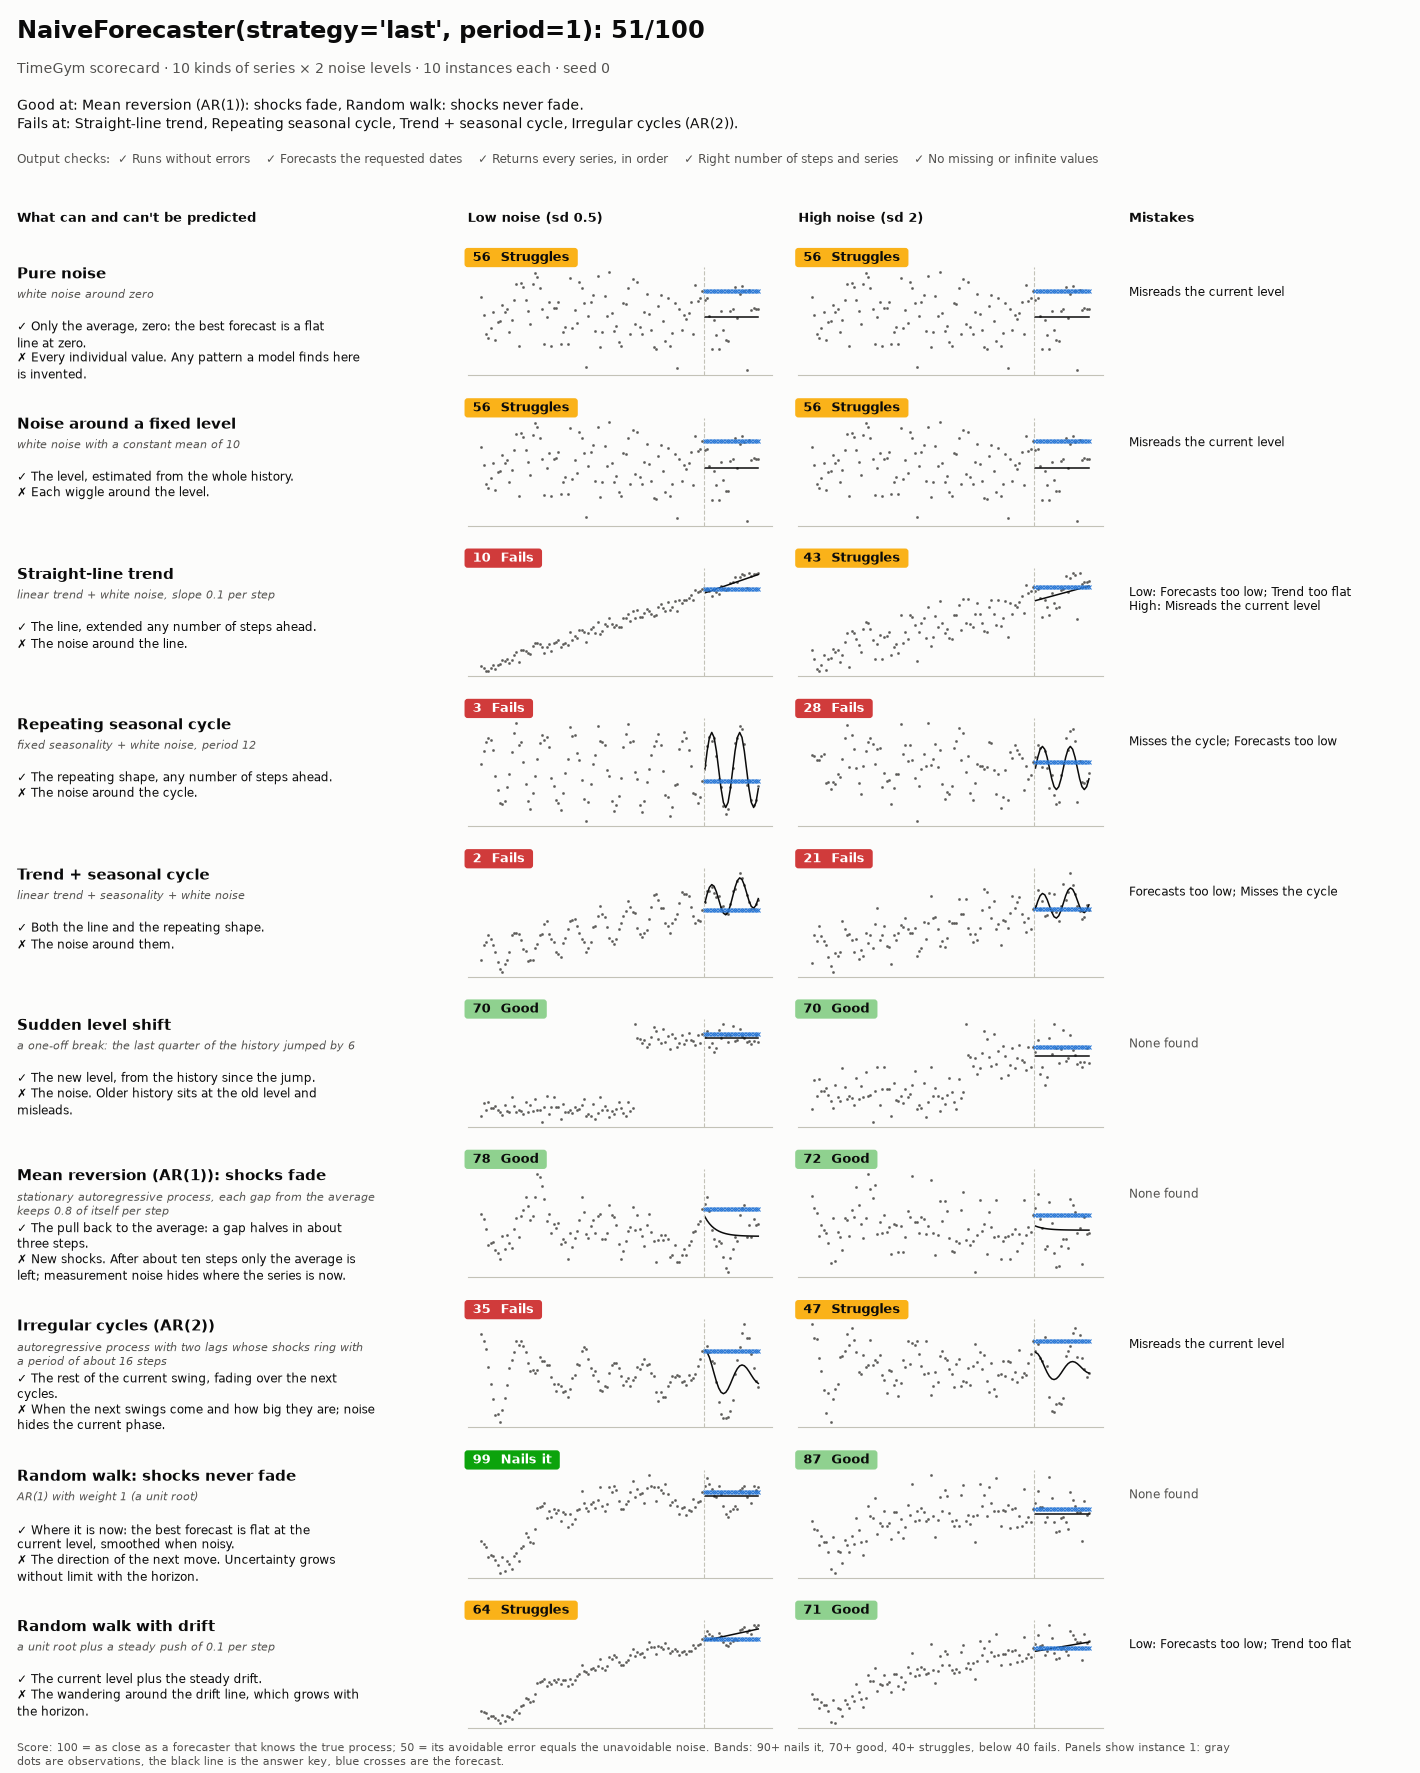

In [14]:
from timegym import Pipeline, NaiveForecaster

card = scorecard(Pipeline(NaiveForecaster()))
assert card.table.set_index(["pattern", "noise"]).loc[("random_walk", "Low noise"), "score"] >= 90
card

Read it row by row. The random walk drops at high noise: the last value is now
partly noise, and the answer key smooths it away. Pure noise and the fixed
level score about 50, as theory says: copying one noisy value doubles the
error of the best forecast, the average. The same scorecard prints as Markdown,
for logs and pull requests.

In [15]:
print(card)

## NaiveForecaster(strategy='last', period=1): 51/100

TimeGym scorecard: 10 kinds of series x 2 noise levels, 10 instances each, seed 0.

| Pattern | Low noise | High noise | Mistakes |
|---|---|---|---|
| Pure noise | 56 Struggles | 56 Struggles | Misreads the current level |
| Noise around a fixed level | 56 Struggles | 56 Struggles | Misreads the current level |
| Straight-line trend | 10 Fails | 43 Struggles | Low: Forecasts too low; Trend too flat · High: Misreads the current level |
| Repeating seasonal cycle | 3 Fails | 28 Fails | Misses the cycle; Forecasts too low |
| Trend + seasonal cycle | 2 Fails | 21 Fails | Forecasts too low; Misses the cycle |
| Sudden level shift | 70 Good | 70 Good | none found |
| Mean reversion (AR(1)): shocks fade | 78 Good | 72 Good | none found |
| Irregular cycles (AR(2)) | 35 Fails | 47 Struggles | Misreads the current level |
| Random walk: shocks never fade | 99 Nails it | 87 Good | none found |
| Random walk with drift | 64 Struggles | 71 G

## A forecaster that learns

A ridge regression on the last 24 values, applied step by step, learns trends,
cycles and the pull back to the average from the history. The compact view
keeps only the scores and the mistakes.

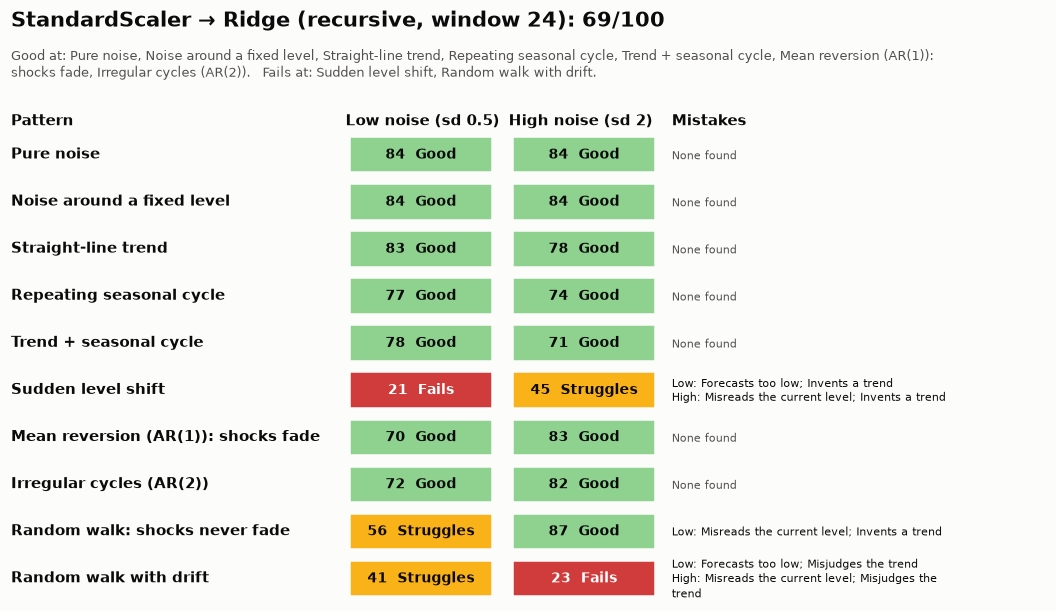

Good at: Pure noise, Noise around a fixed level, Straight-line trend, Repeating seasonal cycle, Trend + seasonal cycle, Mean reversion (AR(1)): shocks fade, Irregular cycles (AR(2))
Fails at: Sudden level shift, Random walk with drift


In [16]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

ridge = scorecard(Pipeline(window_length=24).add(StandardScaler()).add(Ridge(alpha=1.0)))
ridge.plot(compact=True)
plt.show()
print(f"Good at: {', '.join(ridge.good_at)}")
print(f"Fails at: {', '.join(ridge.fails_at)}")

## Bugs it names

Two common bugs. The first model copies the last cycle but slices it one step too
early, so every value arrives one step late. The second gets the values right and
the dates wrong: it labels its forecast from the last observed step. Neither
raises an error.

In [17]:
class SeasonalCopyOffByOne:
    """Copy the last cycle of 12, sliced one step too early."""

    def fit(self, context):
        self.context = context

    def predict(self, future_index):
        last_cycle = self.context.iloc[-13:-1].to_numpy()  # should be iloc[-12:]
        repeats = -(-len(future_index) // 12)
        values = np.tile(last_cycle, (repeats, 1))[:len(future_index)]
        return pd.DataFrame(values, index=future_index, columns=self.context.columns)


class LastValueWrongDates:
    """Repeat the last value, labelled from the last observed step."""

    def fit(self, context):
        self.last = context.iloc[-1]

    def predict(self, future_index):
        return pd.DataFrame([self.last] * len(future_index), index=future_index - 1)


late = scorecard(Pipeline(SeasonalCopyOffByOne()), ["seasonal"])
dates = scorecard(Pipeline(LastValueWrongDates()), ["seasonal"])
assert "Values one step late" in late.table.loc[0, "mistakes"]
assert dates.table["score"].eq(0).all()
display(pd.concat([late.table, dates.table], keys=["Off by one", "Wrong dates"])[["noise", "score", "mistakes"]])
display(pd.DataFrame(dates.checks))

noise      score  \
Off by one  0   Low noise  15.050073   
            1  High noise  42.139169   
Wrong dates 0   Low noise   0.000000   
            1  High noise   0.000000   

                                                   mistakes  
Off by one  0                          Values one step late  
            1                                    Too wiggly  
Wrong dates 0  Wrong dates: shifted 1 step early (10 of 10)  
            1  Wrong dates: shifted 1 step early (10 of 10)

,check,title,passed,failed
0,runs,Runs without errors,20,0
1,dates,Forecasts the requested dates,0,20
2,series,"Returns every series, in order",20,0
3,shape,Right number of steps and series,20,0
4,finite,No missing or infinite values,20,0


The off-by-one copy keeps valid dates and shapes, so only its error pattern gives
it away; at high noise the shift is buried and it reads as wiggles. The wrong
dates never reach scoring: the date check fails first and says how far the dates
moved.

## Seeds and instances

One seed drives the whole scorecard: instance `i` of every cell uses seed
`seed + i`, so the low- and high-noise columns see the same random draws.
More instances make the scores steadier; 20 or 30 suit tuning a model.
`seed=None` draws a fresh seed and records it, so any scorecard can be rerun.

In [18]:
fresh = scorecard(Pipeline(NaiveForecaster()), ["random_walk"], instances=30, seed=None)
rerun = scorecard(Pipeline(NaiveForecaster()), ["random_walk"], instances=30, seed=fresh.seed)
assert rerun.table["score"].equals(fresh.table["score"])
fresh.table[["noise", "score", "verdict", "unavoidable_mse", "avoidable_mse"]].round(3)

,noise,score,verdict,unavoidable_mse,avoidable_mse
0,Low noise,95.407,Nails it,3.530,0.170
1,High noise,62.072,Struggles,8.008,4.893


## Edit, run, export

After editing a source cell, **restart this kernel and Run All**, then export the
package: `python tools/export_notebooks.py`.

[Pipeline](07_pipeline.ipynb) · [Reports](10_reports_and_replay.ipynb) · [Synthetic data](01_synthetic_data.ipynb) · [All notebooks](README.md)